## Modeling: Baseline CV (tanpa tuning)

input: hasil `01-preprocessing.ipynb` di `data/processed/`. **hanya bagian train** yg dipakai, test set tetap dikunci.

eksperimen:
- **task**: `y_dm` (DM vs bukan DM), `y_abn` (abnormal vs NGR), `y3` (3 kelas)
- **feature set** (RQ1): F1 non-lab, F2 combined
- **model** (RQ3): Logistic Regression, Random Forest, XGBoost, TabPFN, semua pakai hyperparameter default. ditambah **CDRS** (Chinese Diabetes Risk Score) sebagai pembanding klinis untuk task biner.
- **imbalance**: `none` dan `class_weight`. SMOTE/RUS belum.

skema CV: repeated stratified 5-fold. split fold-nya **sama untuk semua run** (stratify ke `y3`), jadi perbandingan antar model/feature set bisa dihitung berpasangan per fold.

imputasi median dan scaling ada di dalam pipeline, di-fit di train fold saja.

**checkpoint**: setiap fold disimpan ke `results/checkpoints/<run_id>/`. kalau notebook berhenti di tengah, jalankan ulang saja, fold yg sudah selesai tidak diulang.

### Import Dependencies

In [1]:
import json
import platform
import time
import traceback
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
    f1_score, log_loss, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

### Konfigurasi

ubah di sini kalau mau menambah/mengurangi eksperimen.

In [2]:
RANDOM_STATE = 42
N_SPLITS = 5
N_REPEATS = 3
REPEATS_PER_MODEL = {"TabPFN": 1}   # TabPFN lambat di CPU, cukup 1 repeat dulu

TASKS = ["y_dm", "y_abn", "y3"]
FEATURE_SETS = ["F1_nonlab", "F2_combined"]
MODELS = ["LR", "RF", "XGB", "TabPFN"]
IMBALANCE = ["none", "class_weight"]
JALANKAN_CDRS = True
TABPFN_VERSION = None               # None = versi default terbaru; contoh lain: "v2"

FOLDER_DATA = Path("data/processed")
FOLDER_HASIL = Path("results")
FOLDER_CKPT = FOLDER_HASIL / "checkpoints"
for sub in ["checkpoints", "oof", "importance", "confusion", "figures"]:
    (FOLDER_HASIL / sub).mkdir(parents=True, exist_ok=True)

NAMA_KELAS = {0: "NGR", 1: "Prediabetes", 2: "DM"}
NAMA_TASK = {"y_dm": "DM vs bukan DM", "y_abn": "Abnormal vs NGR", "y3": "3 kelas"}

### Load Data

In [3]:
data = pd.read_csv(FOLDER_DATA / "diabetes_clean.csv")
with open(FOLDER_DATA / "feature_sets.json") as f:
    meta = json.load(f)
FITUR = meta["feature_sets"]

train = data[data["split"] == "train"].reset_index(drop=True)
print("train:", train.shape, "| test (dikunci, tidak dipakai):", (data["split"] == "test").sum())
for nama in ["F1_nonlab", "F2_combined", "cdrs"]:
    print(f"{nama}: {len(FITUR[nama])} fitur")
train["y3"].map(NAMA_KELAS).value_counts()

train: (4698, 76) | test (dikunci, tidak dipakai): 1175
F1_nonlab: 25 fitur
F2_combined: 71 fitur
cdrs: 6 fitur


y3
NGR            3555
Prediabetes     897
DM              246
Name: count, dtype: int64

### CDRS (Chinese Diabetes Risk Score)

skor risiko klinis untuk mendeteksi diabetes yg belum terdiagnosis di China (Zhou et al., *Diabetes Metab Res Rev* 2013; dipakai di pedoman CDS). komponennya umur, jenis kelamin, BMI, lingkar pinggang, tensi sistolik, dan riwayat DM keluarga. total 0–51, cut-off ≥ 25 = risiko tinggi.

CDRS tidak di-fit ke data, jadi ini pembanding yg adil: "apakah ML lebih baik dari skor yg sudah dipakai dokter?". nilai kosong diisi median train fold. **poin per komponen perlu dicek ulang ke paper aslinya sebelum dipakai di paper.**

In [4]:
def poin_cdrs(df):
    umur = pd.cut(df["Age"], [-np.inf, 25, 35, 40, 45, 50, 55, 60, 65, np.inf], right=False,
                  labels=[0, 4, 8, 11, 12, 13, 15, 16, 18]).astype(float)
    bmi = pd.cut(df["BMI"], [-np.inf, 22, 24, 30, np.inf], right=False, labels=[0, 1, 3, 5]).astype(float)
    pinggang_l = pd.cut(df["waist1"], [-np.inf, 75, 80, 85, 90, 95, np.inf], right=False,
                        labels=[0, 3, 5, 7, 8, 10]).astype(float)
    pinggang_p = pd.cut(df["waist1"], [-np.inf, 70, 75, 80, 85, 90, np.inf], right=False,
                        labels=[0, 3, 5, 7, 8, 10]).astype(float)
    pinggang = np.where(df["Male"] == 1, pinggang_l, pinggang_p)
    tensi = pd.cut(df["Bpsys"], [-np.inf, 110, 120, 130, 140, 150, 160, np.inf], right=False,
                   labels=[0, 1, 3, 6, 7, 8, 10]).astype(float)
    return umur + 2 * df["Male"] + bmi + pinggang + tensi + 6 * df["DMfamilyHistory"]


class CDRS(BaseEstimator, ClassifierMixin):
    """skor CDRS dibungkus jadi 'model' supaya bisa masuk loop CV yg sama."""
    CUTOFF = 25
    SKOR_MAKS = 51

    def fit(self, X, y):
        self.median_ = X.median()
        self.classes_ = np.unique(y)
        return self

    def skor(self, X):
        return poin_cdrs(X.fillna(self.median_)).to_numpy()

    def predict_proba(self, X):
        p = self.skor(X) / self.SKOR_MAKS
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.skor(X) >= self.CUTOFF).astype(int)


skor_train = poin_cdrs(train[FITUR["cdrs"]].fillna(train[FITUR["cdrs"]].median()))
skor_train.groupby(train["y3"].map(NAMA_KELAS)).describe().round(1)

,count,mean,std,min,25%,50%,75%,max
y3,,,,,,,,
DM,246.0,23.5,7.7,3.0,19.0,24.0,29.0,44.0
NGR,3555.0,14.7,8.3,0.0,8.0,15.0,21.0,42.0
Prediabetes,897.0,19.1,8.4,0.0,13.0,19.0,25.0,45.0


### Model

semua hyperparameter **default**. satu-satunya yg diubah:
- `max_iter` LR dinaikkan supaya konvergen (bukan tuning).
- `random_state` dan `n_jobs` supaya hasil bisa diulang.

`class_weight`: LR dan RF pakai `class_weight="balanced"`, XGBoost pakai `sample_weight` balanced (efeknya sama). TabPFN tidak punya opsi ini, jadi hanya `none`.

**TabPFN butuh setup sekali**: model TabPFN di HuggingFace terkunci (gated). buka halaman model TabPFN di huggingface.co, setujui lisensinya, lalu login dengan `hf auth login` atau set environment variable `HF_TOKEN`. TabPFN juga jauh lebih cepat di GPU (misalnya Colab). kalau belum di-setup, run TabPFN akan tercatat `error` di `run_log.csv` dan run lain tetap jalan. setelah setup, jalankan ulang notebook: fold model lain dimuat dari checkpoint, yg dikerjakan hanya TabPFN.

TabPFN dan XGBoost bisa menerima NaN, tapi supaya perbandingannya setara, LR/RF/XGB sama-sama diberi imputasi median. TabPFN dibiarkan memakai preprocessing bawaannya.

In [5]:
def buat_model(nama, imbalance, seed):
    cw = "balanced" if imbalance == "class_weight" else None
    imputer = ("imputer", SimpleImputer(strategy="median"))
    if nama == "LR":
        return Pipeline([imputer, ("scaler", StandardScaler()),
                         ("model", LogisticRegression(max_iter=5000, class_weight=cw, random_state=seed))])
    if nama == "RF":
        return Pipeline([imputer, ("model", RandomForestClassifier(class_weight=cw, n_jobs=-1, random_state=seed))])
    if nama == "XGB":
        return Pipeline([imputer, ("model", XGBClassifier(n_jobs=-1, random_state=seed, verbosity=0))])
    if nama == "TabPFN":
        from tabpfn import TabPFNClassifier
        if TABPFN_VERSION is None:
            return TabPFNClassifier(random_state=seed, ignore_pretraining_limits=True)
        from tabpfn.constants import ModelVersion
        return TabPFNClassifier.create_default_for_version(
            ModelVersion(TABPFN_VERSION), random_state=seed, ignore_pretraining_limits=True)
    if nama == "CDRS":
        return CDRS()
    raise ValueError(nama)


def fit_model(model, nama, imbalance, X, y):
    if nama == "XGB" and imbalance == "class_weight":
        model.fit(X, y, model__sample_weight=compute_sample_weight("balanced", y))
    else:
        model.fit(X, y)
    return model


def ambil_importance(model, nama, kolom):
    """LR: |koefisien| (fitur sudah di-scale), RF/XGB: importance bawaan. TabPFN/CDRS: tidak ada."""
    if nama == "LR":
        coef = model.named_steps["model"].coef_
        return pd.Series(np.abs(coef).mean(axis=0), index=kolom)
    if nama in ("RF", "XGB"):
        return pd.Series(model.named_steps["model"].feature_importances_, index=kolom)
    return None

### Metrik

semua metrik dihitung di validation fold.

- **biner**: AUROC dan AUPRC (utama, tidak tergantung threshold), Brier score (kalibrasi), lalu sensitivity, specificity, F1, balanced accuracy pada threshold 0,5 (CDRS: cut-off 25). ditambah `sens_at_spec80`: sensitivity saat specificity 80%, gambaran kalau dipakai untuk skrining.
- **3 kelas**: macro-F1, balanced accuracy, AUROC one-vs-rest (macro dan per kelas), recall per kelas, log loss. prediksi kelas = argmax.

catatan: tanpa `class_weight`, threshold 0,5 hampir pasti membuat sensitivity rendah karena kelasnya timpang. itu sebabnya AUROC/AUPRC yg dipakai untuk membandingkan model.

In [6]:
def metrik_biner(y, proba, pred):
    fpr, tpr, _ = roc_curve(y, proba)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "auroc": roc_auc_score(y, proba),
        "auprc": average_precision_score(y, proba),
        "brier": brier_score_loss(y, np.clip(proba, 0, 1)),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y, pred, zero_division=0),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "sens_at_spec80": tpr[fpr <= 0.20].max(),
        "prevalence": y.mean(),
    }


def metrik_multikelas(y, proba, pred):
    hasil = {
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "auroc_ovr_macro": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        "log_loss": log_loss(y, np.clip(proba, 1e-15, 1), labels=[0, 1, 2]),
    }
    recall = recall_score(y, pred, average=None, labels=[0, 1, 2], zero_division=0)
    for k, nama in NAMA_KELAS.items():
        hasil[f"recall_{nama}"] = recall[k]
        hasil[f"auroc_{nama}_vs_rest"] = roc_auc_score((y == k).astype(int), proba[:, k])
    return hasil

### Daftar Run

run_id = `task__featureset__model__imbalance`. CDRS punya feature set sendiri (`cdrs`) dan hanya untuk task biner. TabPFN ditaruh paling akhir karena paling lama.

In [7]:
RUNS = []
if JALANKAN_CDRS:
    for task in TASKS:
        if task != "y3":
            RUNS.append((task, "cdrs", "CDRS", "none"))
for model in MODELS:
    for task in TASKS:
        for fs in FEATURE_SETS:
            for imb in IMBALANCE:
                if model == "TabPFN" and imb != "none":
                    continue
                RUNS.append((task, fs, model, imb))

run_id = lambda r: "__".join(r)
print("jumlah run:", len(RUNS))
pd.DataFrame(RUNS, columns=["task", "feature_set", "model", "imbalance"]).groupby(["model", "imbalance"]).size()

jumlah run: 44


model   imbalance   
CDRS    none            2
LR      class_weight    6
        none            6
RF      class_weight    6
        none            6
TabPFN  none            6
XGB     class_weight    6
        none            6
dtype: int64

### Split CV

dibuat sekali, dipakai semua run. stratify ke `y3` supaya proporsi NGR/prediabetes/DM sama di tiap fold, dan supaya ketiga task memakai fold yg identik. index fold juga disimpan.

In [8]:
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
FOLDS = []
for i, (idx_tr, idx_va) in enumerate(cv.split(train, train["y3"])):
    FOLDS.append({"repeat": i // N_SPLITS, "fold": i % N_SPLITS, "idx_tr": idx_tr, "idx_va": idx_va})

pd.DataFrame([{"repeat": f["repeat"], "fold": f["fold"], "idx": i}
              for f in FOLDS for i in f["idx_va"]]).to_csv(FOLDER_HASIL / "cv_folds.csv", index=False)
print(len(FOLDS), "fold (", N_REPEATS, "repeat x", N_SPLITS, "fold )")

15 fold ( 3 repeat x 5 fold )


### Jalankan

untuk setiap run dan setiap fold: cek checkpoint → kalau belum ada, fit model di train fold, prediksi validation fold, hitung metrik, simpan checkpoint. kalau satu run error (misalnya TabPFN gagal download model), run itu dicatat sebagai error dan run lain tetap jalan.

In [9]:
def jalankan_fold(task, fs, nama, imb, f):
    X = train[FITUR[fs]]
    y = train[task].to_numpy()
    X_tr, X_va = X.iloc[f["idx_tr"]], X.iloc[f["idx_va"]]
    y_tr, y_va = y[f["idx_tr"]], y[f["idx_va"]]

    seed = RANDOM_STATE + f["repeat"]
    model = buat_model(nama, imb, seed)
    t0 = time.time()
    fit_model(model, nama, imb, X_tr, y_tr)
    t_fit = time.time() - t0
    t0 = time.time()
    proba = model.predict_proba(X_va)
    t_pred = time.time() - t0

    if task == "y3":
        pred = proba.argmax(axis=1)
        m = metrik_multikelas(y_va, proba, pred)
    else:
        pred = model.predict(X_va) if nama == "CDRS" else (proba[:, 1] >= 0.5).astype(int)
        proba = proba[:, 1]
        m = metrik_biner(y_va, proba, pred)

    return {
        "repeat": f["repeat"], "fold": f["fold"], "idx_va": f["idx_va"],
        "y_true": y_va, "proba": proba, "pred": pred, "metrik": m,
        "importance": ambil_importance(model, nama, FITUR[fs]),
        "fit_sec": t_fit, "pred_sec": t_pred,
    }


LOG_RUN = []
for r in RUNS:
    task, fs, nama, imb = r
    rid = run_id(r)
    folder = FOLDER_CKPT / rid
    folder.mkdir(exist_ok=True)
    (folder / "error.txt").unlink(missing_ok=True)
    n_rep = REPEATS_PER_MODEL.get(nama, N_REPEATS)
    folds_run = [f for f in FOLDS if f["repeat"] < n_rep]

    t0, baru, status, pesan = time.time(), 0, "ok", ""
    try:
        for f in folds_run:
            ckpt = folder / f"r{f['repeat']}_f{f['fold']}.joblib"
            if ckpt.exists():
                continue
            tmp = ckpt.with_suffix(".tmp")
            joblib.dump(jalankan_fold(task, fs, nama, imb, f), tmp)
            tmp.replace(ckpt)   # rename setelah selesai tulis, supaya checkpoint tidak pernah setengah jadi
            baru += 1
    except Exception as e:
        status, pesan = "error", f"{type(e).__name__}: {e}"
        (folder / "error.txt").write_text(traceback.format_exc())

    selesai = len(list(folder.glob("r*_f*.joblib")))
    LOG_RUN.append({"run_id": rid, "task": task, "feature_set": fs, "model": nama, "imbalance": imb,
                    "status": status, "fold_selesai": selesai, "fold_target": len(folds_run),
                    "fold_baru": baru, "detik": round(time.time() - t0, 1), "pesan": pesan[:300]})
    print(f"[{status:5}] {rid:45} {selesai:2}/{len(folds_run)} fold  (+{baru} baru, {time.time() - t0:6.1f} s)  {pesan[:80]}")

log_run = pd.DataFrame(LOG_RUN)
log_run.to_csv(FOLDER_HASIL / "run_log.csv", index=False)

[ok   ] y_dm__cdrs__CDRS__none                        15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_abn__cdrs__CDRS__none                       15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_dm__F1_nonlab__LR__none                     15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_dm__F1_nonlab__LR__class_weight             15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_dm__F2_combined__LR__none                   15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_dm__F2_combined__LR__class_weight           15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_abn__F1_nonlab__LR__none                    15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_abn__F1_nonlab__LR__class_weight            15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_abn__F2_combined__LR__none                  15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y_abn__F2_combined__LR__class_weight          15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y3__F1_nonlab__LR__none                       15/15 fold  (+0 baru,    0.0 s)  
[ok   ] y3__F1_nonlab__LR__class

### Kumpulkan Hasil

semua checkpoint dibaca ulang lalu disimpan jadi:

| file | isi |
|---|---|
| `results/cv_fold_metrics.csv` | metrik per run per fold |
| `results/cv_summary.csv` | rata-rata dan std per run |
| `results/oof/<run_id>.csv` | prediksi out-of-fold (probabilitas) per orang |
| `results/importance/<run_id>.csv` | feature importance rata-rata antar fold |
| `results/confusion/<run_id>.csv` | confusion matrix (jumlah semua fold, dibagi jumlah repeat) |
| `results/run_log.csv` | status, waktu, error tiap run |
| `results/config.json` | konfigurasi dan versi library |

In [10]:
baris_fold, baris_ringkas = [], []
for r in RUNS:
    task, fs, nama, imb = r
    rid = run_id(r)
    ckpts = sorted((FOLDER_CKPT / rid).glob("r*_f*.joblib"))
    if not ckpts:
        continue
    hasil = [joblib.load(p) for p in ckpts]
    info = {"run_id": rid, "task": task, "feature_set": fs, "model": nama, "imbalance": imb}

    for h in hasil:
        baris_fold.append({**info, "repeat": h["repeat"], "fold": h["fold"], **h["metrik"],
                           "fit_sec": h["fit_sec"], "pred_sec": h["pred_sec"]})

    # prediksi out-of-fold
    oof = []
    for h in hasil:
        o = pd.DataFrame({"idx": h["idx_va"], "NO": train.loc[h["idx_va"], "NO"].to_numpy(),
                          "repeat": h["repeat"], "fold": h["fold"], "y_true": h["y_true"], "pred": h["pred"]})
        if task == "y3":
            for k, n in NAMA_KELAS.items():
                o[f"proba_{n}"] = h["proba"][:, k]
        else:
            o["proba"] = h["proba"]
        oof.append(o)
    pd.concat(oof).sort_values(["repeat", "idx"]).to_csv(FOLDER_HASIL / "oof" / f"{rid}.csv", index=False)

    # confusion matrix
    label = [0, 1, 2] if task == "y3" else [0, 1]
    n_rep = len({h["repeat"] for h in hasil})
    cm = sum(confusion_matrix(h["y_true"], h["pred"], labels=label) for h in hasil) / n_rep
    nama_label = [NAMA_KELAS[k] for k in label] if task == "y3" else ["negatif", "positif"]
    pd.DataFrame(cm, index=[f"true_{n}" for n in nama_label],
                 columns=[f"pred_{n}" for n in nama_label]).round(1).to_csv(FOLDER_HASIL / "confusion" / f"{rid}.csv")

    # feature importance
    imp = [h["importance"] for h in hasil if h["importance"] is not None]
    if imp:
        imp = pd.concat(imp, axis=1)
        (pd.DataFrame({"mean": imp.mean(axis=1), "std": imp.std(axis=1)})
           .sort_values("mean", ascending=False)
           .to_csv(FOLDER_HASIL / "importance" / f"{rid}.csv", index_label="fitur"))

fold_metrics = pd.DataFrame(baris_fold)
fold_metrics.to_csv(FOLDER_HASIL / "cv_fold_metrics.csv", index=False)

kolom_info = ["run_id", "task", "feature_set", "model", "imbalance"]
kolom_metrik = [c for c in fold_metrics.columns if c not in kolom_info + ["repeat", "fold"]]
g = fold_metrics.groupby(kolom_info, sort=False)
summary = g[kolom_metrik].mean().add_suffix("_mean").join(g[kolom_metrik].std().add_suffix("_std"))
summary.insert(0, "n_fold", g.size())
summary = summary.reset_index()
summary.to_csv(FOLDER_HASIL / "cv_summary.csv", index=False)

config = {
    "random_state": RANDOM_STATE, "n_splits": N_SPLITS, "n_repeats": N_REPEATS,
    "repeats_per_model": REPEATS_PER_MODEL, "tasks": TASKS, "feature_sets": FEATURE_SETS,
    "models": MODELS, "imbalance": IMBALANCE, "n_train": int(len(train)),
    "versi": {"python": platform.python_version(), "sklearn": sklearn.__version__,
              "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
try:
    import tabpfn
    config["versi"]["tabpfn"] = tabpfn.__version__
except ImportError:
    pass
with open(FOLDER_HASIL / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("fold tersimpan:", len(fold_metrics), "| run:", len(summary))

fold tersimpan: 570 | run: 38


## Hasil

### Task biner: DM vs bukan DM dan abnormal vs NGR

angka = rata-rata ± std antar fold.

In [11]:
def tampil(df, metrik):
    out = df[["task", "feature_set", "model", "imbalance", "n_fold"]].copy()
    for m in metrik:
        out[m] = df[f"{m}_mean"].map("{:.3f}".format) + " ± " + df[f"{m}_std"].map("{:.3f}".format)
    return out

METRIK_BINER = ["auroc", "auprc", "brier", "sens_at_spec80", "sensitivity", "specificity", "balanced_acc"]
for task in ["y_dm", "y_abn"]:
    print(f"\n=== {NAMA_TASK[task]} ===")
    s = summary[summary["task"] == task].sort_values("auroc_mean", ascending=False)
    display(tampil(s, METRIK_BINER))


=== DM vs bukan DM ===


,task,feature_set,model,imbalance,n_fold,auroc,auprc,brier,sens_at_spec80,sensitivity,specificity,balanced_acc
4,y_dm,F2_combined,LR,none,15,0.786 ± 0.022,0.260 ± 0.052,0.045 ± 0.002,0.607 ± 0.056,0.102 ± 0.039,0.994 ± 0.003,0.548 ± 0.019
5,y_dm,F2_combined,LR,class_weight,15,0.777 ± 0.026,0.256 ± 0.054,0.164 ± 0.007,0.590 ± 0.063,0.614 ± 0.062,0.776 ± 0.017,0.695 ± 0.028
17,y_dm,F2_combined,RF,class_weight,15,0.776 ± 0.015,0.194 ± 0.026,0.046 ± 0.001,0.562 ± 0.080,0.005 ± 0.009,1.000 ± 0.000,0.503 ± 0.005
28,y_dm,F2_combined,XGB,none,15,0.776 ± 0.020,0.235 ± 0.038,0.048 ± 0.002,0.600 ± 0.052,0.083 ± 0.035,0.994 ± 0.002,0.538 ± 0.017
29,y_dm,F2_combined,XGB,class_weight,15,0.776 ± 0.026,0.240 ± 0.034,0.049 ± 0.003,0.604 ± 0.055,0.138 ± 0.038,0.988 ± 0.003,0.563 ± 0.019
16,y_dm,F2_combined,RF,none,15,0.774 ± 0.021,0.254 ± 0.025,0.045 ± 0.001,0.592 ± 0.052,0.049 ± 0.023,1.000 ± 0.001,0.524 ± 0.011
3,y_dm,F1_nonlab,LR,class_weight,15,0.766 ± 0.032,0.160 ± 0.025,0.189 ± 0.006,0.579 ± 0.066,0.672 ± 0.084,0.723 ± 0.016,0.698 ± 0.038
2,y_dm,F1_nonlab,LR,none,15,0.764 ± 0.031,0.162 ± 0.028,0.048 ± 0.001,0.563 ± 0.068,0.004 ± 0.008,0.998 ± 0.002,0.501 ± 0.004
15,y_dm,F1_nonlab,RF,class_weight,15,0.762 ± 0.028,0.160 ± 0.023,0.048 ± 0.001,0.558 ± 0.065,0.005 ± 0.009,0.999 ± 0.001,0.502 ± 0.005
26,y_dm,F1_nonlab,XGB,none,15,0.756 ± 0.021,0.152 ± 0.024,0.052 ± 0.002,0.539 ± 0.055,0.042 ± 0.019,0.991 ± 0.004,0.516 ± 0.009



=== Abnormal vs NGR ===


,task,feature_set,model,imbalance,n_fold,auroc,auprc,brier,sens_at_spec80,sensitivity,specificity,balanced_acc
8,y_abn,F2_combined,LR,none,15,0.700 ± 0.020,0.448 ± 0.029,0.166 ± 0.005,0.463 ± 0.040,0.187 ± 0.021,0.958 ± 0.007,0.573 ± 0.010
9,y_abn,F2_combined,LR,class_weight,15,0.699 ± 0.019,0.446 ± 0.030,0.216 ± 0.006,0.463 ± 0.037,0.614 ± 0.034,0.678 ± 0.018,0.646 ± 0.017
21,y_abn,F2_combined,RF,class_weight,15,0.698 ± 0.019,0.431 ± 0.023,0.167 ± 0.003,0.458 ± 0.028,0.084 ± 0.022,0.983 ± 0.005,0.533 ± 0.010
20,y_abn,F2_combined,RF,none,15,0.686 ± 0.019,0.436 ± 0.022,0.168 ± 0.003,0.436 ± 0.030,0.138 ± 0.016,0.971 ± 0.008,0.555 ± 0.007
7,y_abn,F1_nonlab,LR,class_weight,15,0.680 ± 0.020,0.400 ± 0.026,0.225 ± 0.004,0.449 ± 0.036,0.613 ± 0.038,0.654 ± 0.015,0.633 ± 0.023
6,y_abn,F1_nonlab,LR,none,15,0.679 ± 0.020,0.400 ± 0.026,0.171 ± 0.004,0.444 ± 0.038,0.100 ± 0.015,0.968 ± 0.008,0.534 ± 0.007
33,y_abn,F2_combined,XGB,class_weight,15,0.678 ± 0.016,0.426 ± 0.020,0.191 ± 0.007,0.429 ± 0.044,0.318 ± 0.027,0.876 ± 0.016,0.597 ± 0.015
1,y_abn,cdrs,CDRS,none,15,0.676 ± 0.018,0.390 ± 0.019,0.179 ± 0.004,0.404 ± 0.025,0.316 ± 0.016,0.874 ± 0.008,0.595 ± 0.008
32,y_abn,F2_combined,XGB,none,15,0.676 ± 0.017,0.427 ± 0.022,0.188 ± 0.005,0.434 ± 0.033,0.232 ± 0.024,0.926 ± 0.009,0.579 ± 0.012
19,y_abn,F1_nonlab,RF,class_weight,15,0.659 ± 0.018,0.374 ± 0.014,0.175 ± 0.003,0.392 ± 0.029,0.102 ± 0.015,0.963 ± 0.007,0.533 ± 0.007


### Task 3 kelas

In [12]:
METRIK_MULTI = ["macro_f1", "balanced_acc", "auroc_ovr_macro", "recall_NGR", "recall_Prediabetes", "recall_DM",
                "auroc_Prediabetes_vs_rest", "auroc_DM_vs_rest"]
s = summary[summary["task"] == "y3"].sort_values("auroc_ovr_macro_mean", ascending=False)
tampil(s, METRIK_MULTI)

,task,feature_set,model,imbalance,n_fold,macro_f1,balanced_acc,auroc_ovr_macro,recall_NGR,recall_Prediabetes,recall_DM,auroc_Prediabetes_vs_rest,auroc_DM_vs_rest
12,y3,F2_combined,LR,none,15,0.390 ± 0.023,0.392 ± 0.016,0.708 ± 0.016,0.976 ± 0.007,0.047 ± 0.012,0.152 ± 0.041,0.637 ± 0.022,0.787 ± 0.023
36,y3,F2_combined,XGB,none,15,0.392 ± 0.022,0.388 ± 0.014,0.699 ± 0.012,0.966 ± 0.007,0.087 ± 0.022,0.110 ± 0.033,0.626 ± 0.018,0.788 ± 0.013
25,y3,F2_combined,RF,class_weight,15,0.296 ± 0.009,0.338 ± 0.005,0.698 ± 0.021,0.999 ± 0.001,0.001 ± 0.002,0.014 ± 0.015,0.625 ± 0.027,0.775 ± 0.024
24,y3,F2_combined,RF,none,15,0.331 ± 0.021,0.354 ± 0.011,0.697 ± 0.015,0.993 ± 0.002,0.023 ± 0.012,0.047 ± 0.029,0.614 ± 0.021,0.791 ± 0.015
10,y3,F1_nonlab,LR,none,15,0.313 ± 0.018,0.344 ± 0.010,0.690 ± 0.018,0.986 ± 0.005,0.013 ± 0.009,0.033 ± 0.025,0.626 ± 0.025,0.765 ± 0.031
37,y3,F2_combined,XGB,class_weight,15,0.421 ± 0.027,0.408 ± 0.021,0.689 ± 0.014,0.917 ± 0.010,0.155 ± 0.028,0.152 ± 0.052,0.611 ± 0.017,0.784 ± 0.025
13,y3,F2_combined,LR,class_weight,15,0.413 ± 0.019,0.491 ± 0.029,0.679 ± 0.015,0.617 ± 0.019,0.367 ± 0.042,0.489 ± 0.068,0.567 ± 0.031,0.771 ± 0.022
23,y3,F1_nonlab,RF,class_weight,15,0.303 ± 0.011,0.339 ± 0.006,0.672 ± 0.015,0.991 ± 0.004,0.010 ± 0.007,0.016 ± 0.016,0.589 ± 0.020,0.764 ± 0.025
22,y3,F1_nonlab,RF,none,15,0.319 ± 0.014,0.346 ± 0.007,0.667 ± 0.016,0.985 ± 0.004,0.035 ± 0.012,0.019 ± 0.018,0.590 ± 0.021,0.754 ± 0.024
11,y3,F1_nonlab,LR,class_weight,15,0.391 ± 0.016,0.482 ± 0.029,0.663 ± 0.020,0.609 ± 0.017,0.283 ± 0.037,0.554 ± 0.079,0.543 ± 0.028,0.764 ± 0.034


### RQ1: apakah lab rutin menambah informasi?

selisih F2 − F1 dihitung **berpasangan per fold** (fold-nya sama persis), lalu dirata-rata. kalau selisihnya lebih kecil dari std-nya, tambahan lab belum tentu nyata.

In [13]:
METRIK_UTAMA = {"y_dm": "auroc", "y_abn": "auroc", "y3": "auroc_ovr_macro"}

baris = []
for task, m in METRIK_UTAMA.items():
    d = fold_metrics[fold_metrics["task"] == task]
    w = d.pivot_table(index=["model", "imbalance", "repeat", "fold"], columns="feature_set", values=m)
    if not {"F1_nonlab", "F2_combined"} <= set(w.columns):
        continue
    w = w.dropna(subset=["F1_nonlab", "F2_combined"])
    w["selisih"] = w["F2_combined"] - w["F1_nonlab"]
    for (model, imb), grp in w.groupby(level=["model", "imbalance"]):
        baris.append({"task": task, "metrik": m, "model": model, "imbalance": imb, "n_fold": len(grp),
                      "F1_nonlab": grp["F1_nonlab"].mean(), "F2_combined": grp["F2_combined"].mean(),
                      "selisih_mean": grp["selisih"].mean(), "selisih_std": grp["selisih"].std(),
                      "fold_F2_lebih_baik_%": (grp["selisih"] > 0).mean() * 100})
rq1 = pd.DataFrame(baris).round(3)
rq1.to_csv(FOLDER_HASIL / "rq1_lab_vs_nonlab.csv", index=False)
rq1

,task,metrik,model,imbalance,n_fold,F1_nonlab,F2_combined,selisih_mean,selisih_std,fold_F2_lebih_baik_%
0,y_dm,auroc,LR,class_weight,15,0.766,0.777,0.011,0.022,66.667
1,y_dm,auroc,LR,none,15,0.764,0.786,0.022,0.025,80.000
2,y_dm,auroc,RF,class_weight,15,0.762,0.776,0.015,0.027,66.667
3,y_dm,auroc,RF,none,15,0.744,0.774,0.030,0.022,86.667
4,y_dm,auroc,XGB,class_weight,15,0.749,0.776,0.027,0.030,80.000
5,y_dm,auroc,XGB,none,15,0.756,0.776,0.020,0.020,86.667
6,y_abn,auroc,LR,class_weight,15,0.680,0.699,0.019,0.015,86.667
7,y_abn,auroc,LR,none,15,0.679,0.700,0.021,0.015,93.333
8,y_abn,auroc,RF,class_weight,15,0.659,0.698,0.039,0.015,100.000
9,y_abn,auroc,RF,none,15,0.657,0.686,0.029,0.015,93.333


### RQ3: perbandingan model

dibandingkan pada feature set F2 dan imbalance `none` (satu-satunya setting yg dimiliki semua model), plus CDRS untuk task biner. selisih dihitung berpasangan terhadap Logistic Regression.

In [14]:
baris = []
for task, m in METRIK_UTAMA.items():
    d = fold_metrics[(fold_metrics["task"] == task) & (fold_metrics["imbalance"] == "none")
                     & fold_metrics["feature_set"].isin(["F2_combined", "cdrs"])]
    w = d.pivot_table(index=["repeat", "fold"], columns="model", values=m)
    if "LR" not in w:
        continue
    for model in w.columns:
        pas = w[[model]].join(w[["LR"]], rsuffix="_ref").dropna() if model == "LR" else w[[model, "LR"]].dropna()
        ref = pas["LR_ref"] if model == "LR" else pas["LR"]
        sel = pas[model] - ref
        baris.append({"task": task, "metrik": m, "model": model, "n_fold": len(pas),
                      "mean": pas[model].mean(), "std": pas[model].std(),
                      "selisih_vs_LR": sel.mean(), "selisih_std": sel.std()})
rq3 = pd.DataFrame(baris).sort_values(["task", "mean"], ascending=[True, False]).round(3)
rq3.to_csv(FOLDER_HASIL / "rq3_model_comparison.csv", index=False)
rq3

,task,metrik,model,n_fold,mean,std,selisih_vs_LR,selisih_std
8,y3,auroc_ovr_macro,LR,15,0.708,0.016,0.000,0.000
10,y3,auroc_ovr_macro,XGB,15,0.699,0.012,-0.009,0.013
9,y3,auroc_ovr_macro,RF,15,0.697,0.015,-0.011,0.017
5,y_abn,auroc,LR,15,0.700,0.020,0.000,0.000
6,y_abn,auroc,RF,15,0.686,0.019,-0.014,0.014
4,y_abn,auroc,CDRS,15,0.676,0.018,-0.023,0.017
7,y_abn,auroc,XGB,15,0.676,0.017,-0.023,0.019
1,y_dm,auroc,LR,15,0.786,0.022,0.000,0.000
3,y_dm,auroc,XGB,15,0.776,0.020,-0.010,0.020
2,y_dm,auroc,RF,15,0.774,0.021,-0.012,0.025


### Plot ringkasan AUROC

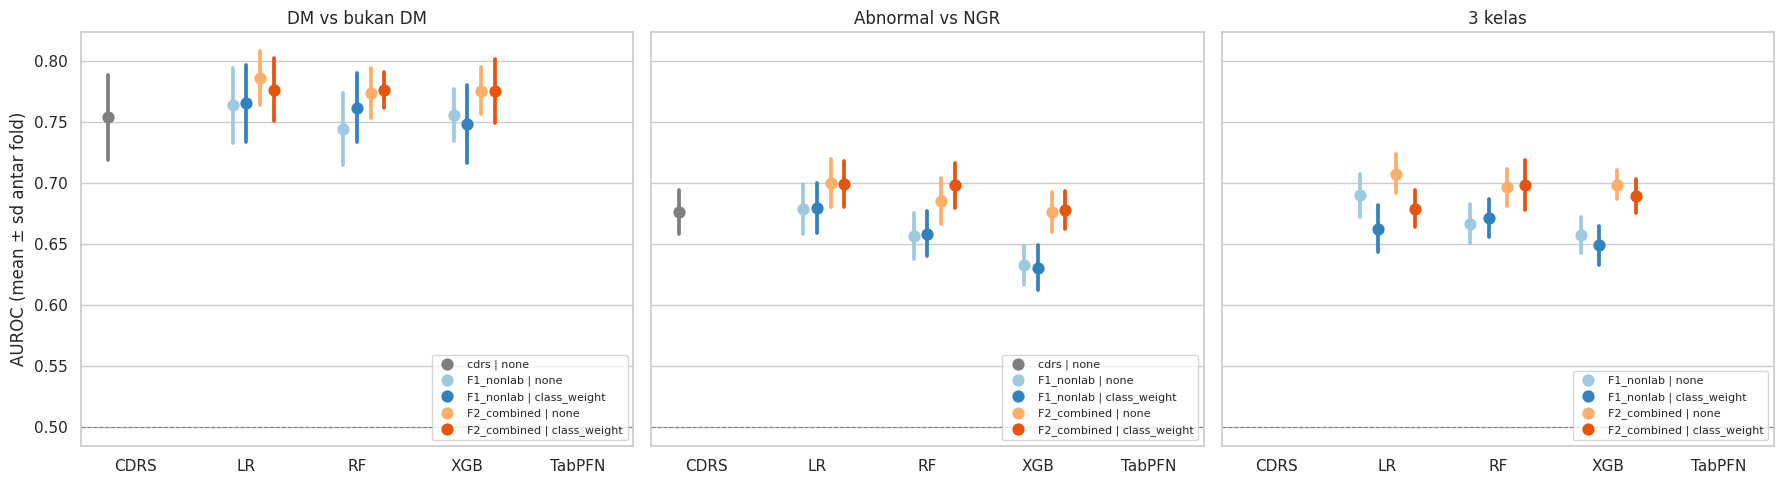

In [15]:
d = fold_metrics.copy()
d["auroc_utama"] = np.where(d["task"] == "y3", d["auroc_ovr_macro"], d["auroc"])
d["setting"] = d["feature_set"] + " | " + d["imbalance"]

URUTAN_SETTING = ["cdrs | none", "F1_nonlab | none", "F1_nonlab | class_weight",
                  "F2_combined | none", "F2_combined | class_weight"]
WARNA_SETTING = dict(zip(URUTAN_SETTING, ["#7f7f7f", "#9ecae1", "#3182bd", "#fdae6b", "#e6550d"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, task in zip(axes, ["y_dm", "y_abn", "y3"]):
    sub = d[d["task"] == task]
    sns.pointplot(data=sub, x="model", y="auroc_utama", hue="setting", order=["CDRS"] + MODELS,
                  hue_order=[h for h in URUTAN_SETTING if h in set(sub["setting"])], palette=WARNA_SETTING,
                  dodge=0.5, errorbar="sd", linestyle="none", ax=ax)
    ax.set_title(NAMA_TASK[task])
    ax.set_xlabel("")
    ax.set_ylabel("AUROC (mean ± sd antar fold)")
    ax.axhline(0.5, color="grey", lw=0.8, ls="--")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FOLDER_HASIL / "figures" / "auroc_summary.png", dpi=200, bbox_inches="tight")
plt.show()

### Feature importance (F2, model terbaik per task)

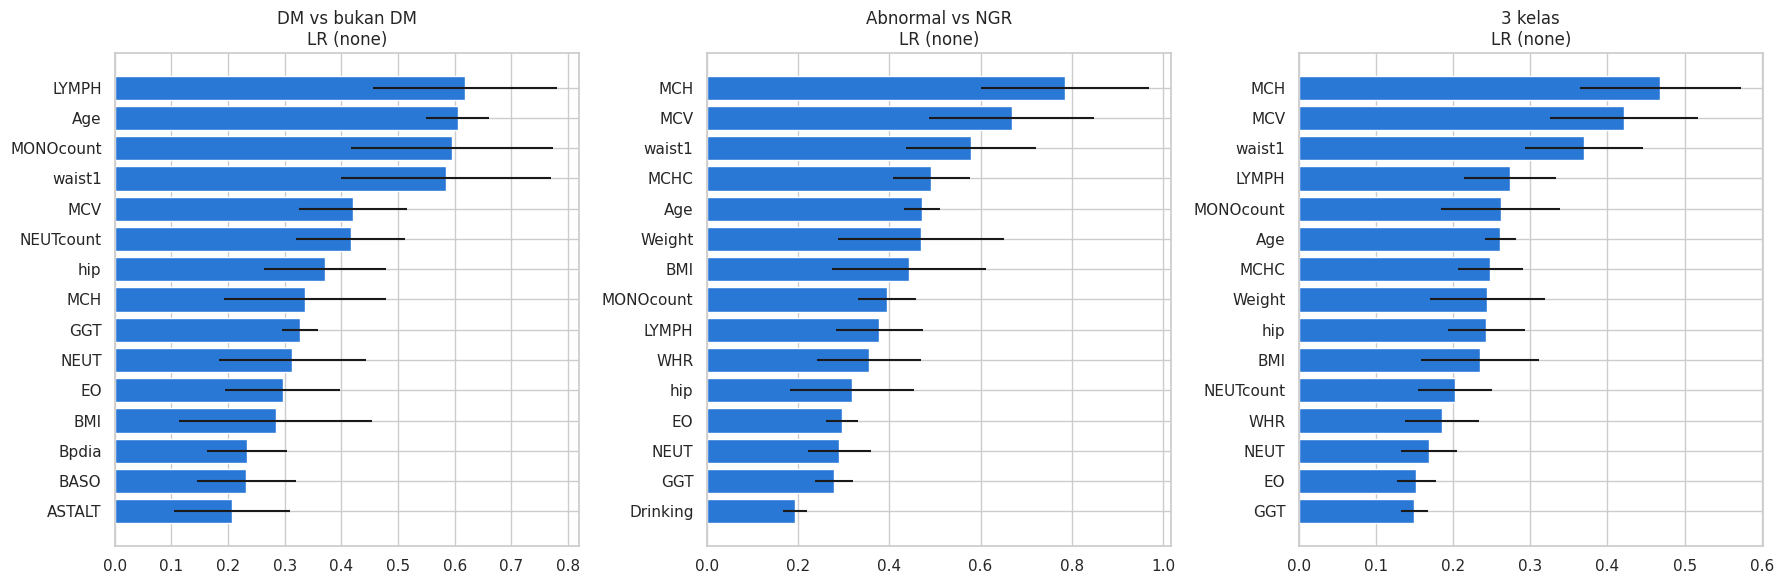

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, task in zip(axes, ["y_dm", "y_abn", "y3"]):
    m = METRIK_UTAMA[task] + "_mean"
    kandidat = summary[(summary["task"] == task) & (summary["feature_set"] == "F2_combined")
                       & summary["model"].isin(["LR", "RF", "XGB"])]
    if kandidat.empty:
        continue
    terbaik = kandidat.sort_values(m, ascending=False).iloc[0]
    imp = pd.read_csv(FOLDER_HASIL / "importance" / f"{terbaik['run_id']}.csv").head(15)
    ax.barh(imp["fitur"][::-1], imp["mean"][::-1], xerr=imp["std"][::-1], color="#2a78d6")
    ax.set_title(f"{NAMA_TASK[task]}\n{terbaik['model']} ({terbaik['imbalance']})")
plt.tight_layout()
plt.savefig(FOLDER_HASIL / "figures" / "feature_importance_top15.png", dpi=200, bbox_inches="tight")
plt.show()

### Status run

In [17]:
log_run[["run_id", "status", "fold_selesai", "fold_target", "detik", "pesan"]]

,run_id,status,fold_selesai,fold_target,detik,pesan
0,y_dm__cdrs__CDRS__none,ok,15,15,0.0,
1,y_abn__cdrs__CDRS__none,ok,15,15,0.0,
2,y_dm__F1_nonlab__LR__none,ok,15,15,0.0,
3,y_dm__F1_nonlab__LR__class_weight,ok,15,15,0.0,
4,y_dm__F2_combined__LR__none,ok,15,15,0.0,
5,y_dm__F2_combined__LR__class_weight,ok,15,15,0.0,
6,y_abn__F1_nonlab__LR__none,ok,15,15,0.0,
7,y_abn__F1_nonlab__LR__class_weight,ok,15,15,0.0,
8,y_abn__F2_combined__LR__none,ok,15,15,0.0,
9,y_abn__F2_combined__LR__class_weight,ok,15,15,0.0,
